# Exploratory baseline: all 222 normalized cultivar classes

This notebook preserves **all 222 case/whitespace-normalized cultivar labels**, including spelling variants. Unlike exterior-only V1, it uses **both exterior and interior images** to retain the full catalog. Scores measure this mixed-view experiment, not exterior-phone-photo performance.

Every class has training representation. Sparse classes may have no validation/test examples; they are explicitly reported as training-only, never silently dropped or split by individual images. Missing-code records remain in training because relationships cannot be established. Codes are conservative accession/location proxies, not verified fruit identities. Exact duplicates and known code groups stay together.

Run top to bottom in the ml-models environment. Frozen ImageNet ResNet-18 features feed a centroid baseline and a 222-output linear head. Whole-image inputs, labels, and specimen groups remain exploratory; label-card shortcuts are possible. Raw files and the mapping CSV are preserved. No new CSV reports.

## 1. Configuration

No class-count threshold or top-class selection. All normalized classes must remain present. Crop review is supported, but restricting to existing reviewed crops may currently remove classes and will stop this full-catalog experiment.

In [1]:
from pathlib import Path
import copy, hashlib, json, random, re, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from PIL import Image, ImageOps
from pillow_heif import register_heif_opener
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
from torchvision.models import resnet18, ResNet18_Weights
from torchvision import transforms

register_heif_opener()
HERE = Path.cwd().resolve()
ML_ROOT = next((p for parent in (HERE, *HERE.parents) for p in (parent, parent / 'ml-models')
                if (p / 'data/manifests/sharepoint_gemini/annotations.jsonl').is_file()), None)
if ML_ROOT is None:
    raise FileNotFoundError('Could not locate ml-models.')
SEED = 4914
EXPECTED_CLASSES = 222
BATCH_SIZE = 16
EPOCHS = 60
PATIENCE = 10
LEARNING_RATE = 0.003
USE_CLASS_WEIGHTS = False
REQUIRE_REVIEWED_CROPS = False
# raw_path -> (left, top, right, bottom), in pixels AFTER EXIF orientation correction.
# Add entries only after verifying the crop retains the whole fruit and removes cards/rulers.
REVIEWED_CROPS = {}
# Raw transcription -> human-approved canonical name. These override proposed aliases.
LABEL_OVERRIDES = {}
REJECTED_PATHS = set()
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else
                      'mps' if torch.backends.mps.is_available() else 'cpu')
# Keep all downloaded weights and model artifacts under this workspace.
torch.hub.set_dir(str(ML_ROOT / 'runs' / '.torch-cache'))
print(f'Device: {DEVICE}; seed: {SEED}')
print('Mode:', 'reviewed crops' if REQUIRE_REVIEWED_CROPS else 'EXPLORATORY mixed-view whole images / available reviewed crops')

Device: cpu; seed: 4914
Mode: EXPLORATORY mixed-view whole images / available reviewed crops


## 2. Load the full catalog

Normalize case and whitespace only; no proposed spelling merges. Preserve all labeled views. Stop on conflicting exact-image labels, missing files, or a changed class count so the experiment cannot quietly discard a class.

In [2]:
manifest_path = ML_ROOT / 'data/manifests/sharepoint_gemini/annotations.jsonl'
with manifest_path.open(encoding='utf-8') as handle:
    records = [json.loads(line) for line in handle if line.strip()]
manifest = pd.json_normalize(records)
manifest['cultivar_raw'] = manifest['annotation.cultivar'].astype('string').str.strip().replace('', pd.NA)
manifest['cultivar'] = manifest.cultivar_raw.str.replace(r'\s+', ' ', regex=True).str.upper()
manifest['code'] = manifest['annotation.specimen_code'].astype('string').str.upper().str.replace(r'\s+', '', regex=True).replace('', pd.NA)
manifest['view'] = manifest['annotation.view_type'].astype('string').str.strip().str.lower().fillna('unknown')
manifest = manifest.sort_values('completed_at', kind='stable').drop_duplicates('raw_path', keep='last')
class_names = sorted(manifest.cultivar.dropna().unique())
if len(class_names) != EXPECTED_CLASSES:
    raise ValueError(f'Expected {EXPECTED_CLASSES} normalized labels; found {len(class_names)}. Review the catalog/configuration.')
class_to_id = {name: i for i, name in enumerate(class_names)}
candidates = manifest.loc[manifest.cultivar.notna()].copy()
candidates['path'] = candidates.raw_path.map(lambda p: ML_ROOT / p)
if not candidates.path.map(Path.is_file).all():
    raise FileNotFoundError('Missing image files; restore them before the full-catalog experiment.')
conflicting_hashes = candidates.dropna(subset=['sha256']).groupby('sha256').cultivar.nunique()
if conflicting_hashes.gt(1).any():
    raise ValueError('An exact image has conflicting labels; resolve it before training.')
if REJECTED_PATHS:
    candidates = candidates.loc[~candidates.raw_path.isin(REJECTED_PATHS)].copy()
if REQUIRE_REVIEWED_CROPS:
    candidates = candidates.loc[candidates.raw_path.isin(REVIEWED_CROPS)].copy()
if set(candidates.cultivar) != set(class_names):
    raise ValueError('Filtering removed a class; review the full-catalog scope rather than silently shrinking it.')
print(f'{len(records):,} annotation records; {len(candidates):,} labeled images; {len(class_names)} classes.')
print('Views:', candidates.view.value_counts().to_dict())
print(f'{candidates.code.isna().sum()} images lack a code; keep their linked groups in training.')

1,408 annotation records; 1,387 labeled images; 222 classes.
Views: {'exterior': 751, 'interior': 635, 'unknown': 1}
23 images lack a code; keep their linked groups in training.


## 3. Group relationships without reducing the catalog

Code alone is shared across cultivar labels. Hash duplicates join groups transitively. Remove redundant exact images only after grouping, then verify all 222 labels remain.

In [3]:
parents = {i: i for i in candidates.index}
def find_group(i):
    while parents[i] != i:
        parents[i] = parents[parents[i]]
        i = parents[i]
    return i

def join_group(a, b):
    parents[find_group(b)] = find_group(a)

for key in ['code', 'sha256']:
    seen = {}
    for i, value in candidates[key].items():
        if pd.isna(value) or not str(value).strip():
            continue
        if value in seen:
            join_group(seen[value], i)
        else:
            seen[value] = i
candidates['group'] = [f'g{find_group(i)}' for i in candidates.index]
valid_hash = candidates.sha256.notna() & candidates.sha256.astype('string').str.strip().ne('')
extra_duplicates = valid_hash & candidates.sha256.duplicated(keep='first')
print(f'Removing {extra_duplicates.sum()} redundant exact-image records after grouping.')
candidates = candidates.loc[~extra_duplicates].copy()
model_df = candidates.copy().reset_index(drop=True)
model_df['class_id'] = model_df.cultivar.map(class_to_id)
assert set(model_df.cultivar) == set(class_names)
coverage = model_df.groupby('cultivar').agg(images=('raw_path', 'size'), groups=('group', 'nunique'))
print(f'{len(model_df):,} distinct image records across all {len(class_names)} classes.')
print('Class images: median', coverage.images.median(), '; range', coverage.images.min(), 'to', coverage.images.max())
print('Classes with one group:', coverage.groups.eq(1).sum())

Removing 1 redundant exact-image records after grouping.
1,386 distinct image records across all 222 classes.
Class images: median 6.0 ; range 1 to 39
Classes with one group: 134


## 4. Build honest held-out subsets

Start with every group in training. Groups containing missing-code images are training-only. Reserve groups for test/validation only if **every affected class retains training data**. Try three-group classes in both holdouts, then two-group classes in test. Constraints and shared codes can leave additional classes training-only. The 60/20/20 proportions are a preference, not a guarantee. Split construction never uses model performance.

In [4]:
def make_catalog_splits(frame, seed=SEED, attempts=100):
    rng = np.random.default_rng(seed)
    groups_by_class = frame.groupby('class_id').group.agg(lambda values: set(values))
    classes_by_group = frame.groupby('group').class_id.agg(lambda values: set(values)).to_dict()
    forced_train = set(frame.loc[frame.code.isna(), 'group'])
    best = None; best_score = None
    for _ in range(attempts):
        assignment = {group: 'train' for group in classes_by_group}
        train_groups = {label: set(groups) for label, groups in groups_by_class.items()}
        ordered = sorted(groups_by_class.index, key=lambda label: (len(groups_by_class[label]), rng.random()))
        for label in ordered:
            groups = groups_by_class[label]
            if len(groups) < 2:
                continue
            desired = ['test', 'validation'] if len(groups) >= 3 else ['test']
            for split in desired:
                if any(assignment[group] == split for group in groups):
                    continue
                choices = [group for group in groups if assignment[group] == 'train' and group not in forced_train
                           and all(len(train_groups[other]) > 1 for other in classes_by_group[group])]
                if not choices:
                    continue
                choices = sorted(choices)
                group = choices[int(rng.integers(len(choices)))]
                assignment[group] = split
                for other in classes_by_group[group]:
                    train_groups[other].remove(group)
        split = frame.group.map(assignment)
        held_classes = [frame.loc[split.eq(name), 'class_id'].nunique() for name in ['validation', 'test']]
        fractions = np.array([split.eq(name).mean() for name in ['train', 'validation', 'test']])
        score = (min(held_classes), sum(held_classes), -float(np.abs(fractions - [0.6, 0.2, 0.2]).sum()))
        if best_score is None or score > best_score:
            best, best_score = split, score
    return best

model_df['split'] = make_catalog_splits(model_df)
assert model_df.groupby('group').split.nunique().max() == 1
assert model_df.dropna(subset=['code']).groupby('code').split.nunique().max() == 1
assert model_df.dropna(subset=['sha256']).groupby('sha256').split.nunique().max() == 1
split_counts = pd.crosstab(model_df.cultivar, model_df.split).reindex(index=class_names, columns=['train', 'validation', 'test'], fill_value=0)
assert split_counts.train.gt(0).all()
assert split_counts.validation.sum() > 0 and split_counts.test.sum() > 0
training_only = split_counts.index[split_counts[['validation', 'test']].sum(axis=1).eq(0)].tolist()
coverage_summary = pd.DataFrame({'images': split_counts.sum(), 'represented_classes': split_counts.gt(0).sum()})
display(coverage_summary)
print(f'{len(training_only)} classes have training examples but no held-out examples.')
print(f'{((split_counts.validation > 0) & (split_counts.test > 0)).sum()} classes appear in both held-out splits.')
print('No known groups cross splits. Full 222-class generalization cannot be measured with this coverage.')

140 classes have training examples but no held-out examples.
33 classes appear in both held-out splits.
No known groups cross splits. Full 222-class generalization cannot be measured with this coverage.


,images,represented_classes
split,,
train,993,222
validation,113,33
test,280,82


## 5. Decode, crop, preserve shape, and inspect inputs

EXIF orientation is applied before crop coordinates. Convert to RGB, pad to a square, resize to 224×224, and apply ImageNet mean/std. Padding preserves fruit shape and avoids center-cropping fruit edges. No grayscale, aggressive color edits, or automatic cropping. Preview before interpreting any experiment.


Whole-image scores are exploratory and may reflect handwritten labels/backgrounds.


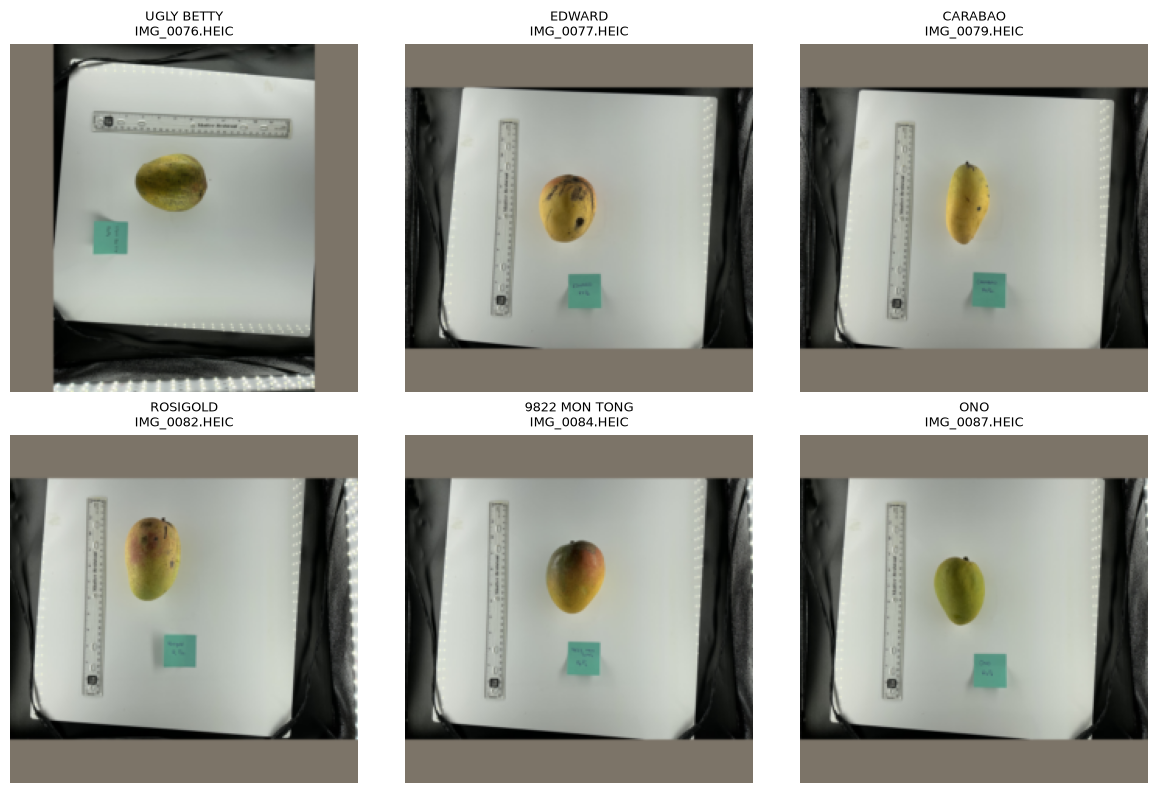

In [5]:
IMAGE_SIZE = 224
MEAN = [0.485, 0.456, 0.406]
STD = [0.229, 0.224, 0.225]
normalize_tensor = transforms.Compose([transforms.ToTensor(), transforms.Normalize(MEAN, STD)])

def prepare_image(row):
    with Image.open(row.path) as opened:
        image = ImageOps.exif_transpose(opened).convert('RGB')
    if row.raw_path in REVIEWED_CROPS:
        left, top, right, bottom = REVIEWED_CROPS[row.raw_path]
        if not (0 <= left < right <= image.width and 0 <= top < bottom <= image.height):
            raise ValueError(f'Invalid oriented-image crop: {row.raw_path}')
        image = image.crop((left, top, right, bottom))
    elif REQUIRE_REVIEWED_CROPS:
        raise ValueError(f'Missing reviewed crop: {row.raw_path}')
    edge = max(image.size)
    square = Image.new('RGB', (edge, edge), color=(124, 116, 104))
    square.paste(image, ((edge - image.width) // 2, (edge - image.height) // 2))
    return square.resize((IMAGE_SIZE, IMAGE_SIZE), Image.Resampling.BILINEAR)

preview_rows = model_df.groupby('cultivar', sort=True).head(1).head(6)
fig, axes = plt.subplots(2, 3, figsize=(12, 8))
for ax, row in zip(axes.flat, preview_rows.itertuples()):
    ax.imshow(prepare_image(row)); ax.set_title(f'{row.cultivar}\n{Path(row.raw_path).name}', fontsize=9)
for ax in axes.flat:
    ax.axis('off')
plt.tight_layout(); plt.show()
print('Whole-image scores are exploratory and may reflect handwritten labels/backgrounds.')

## 6. Load the pretrained feature extractor

ResNet-18 is frozen, including batch-normalization running statistics. The first run downloads approximately 45 MB of ImageNet weights into the workspace cache. If download fails, resolve it before training; random weights are not a transfer-learning substitute.


In [6]:
weights = ResNet18_Weights.IMAGENET1K_V1
backbone = resnet18(weights=weights)
feature_size = backbone.fc.in_features
backbone.fc = nn.Identity()
backbone.requires_grad_(False)
backbone = backbone.to(DEVICE).eval()
print(f'Frozen ResNet-18: {feature_size} features per image; {len(class_names)} target classes.')

Frozen ResNet-18: 512 features per image; 222 target classes.


## 7. Extract deterministic features once

This baseline skips augmentation so frozen features can be reused cheaply. Feature extraction performs no fitting on validation/test data; classifier training uses training rows only. Decode failures stop with the offending path rather than silently changing the split.


In [7]:
features_list = []
started = time.time()
with torch.inference_mode():
    for start in range(0, len(model_df), BATCH_SIZE):
        batch_rows = model_df.iloc[start:start + BATCH_SIZE]
        tensors = []
        for row in batch_rows.itertuples():
            try:
                tensors.append(normalize_tensor(prepare_image(row)))
            except Exception as exc:
                raise RuntimeError(f'Image decode/preprocessing failed: {row.raw_path}') from exc
        features_list.append(backbone(torch.stack(tensors).to(DEVICE)).cpu())
features = torch.cat(features_list).clone()
labels = torch.tensor(model_df.class_id.to_numpy(), dtype=torch.long)
assert features.shape == (len(model_df), feature_size)
assert torch.isfinite(features).all()
indices = {name: torch.tensor(np.flatnonzero(model_df.split.eq(name).to_numpy()), dtype=torch.long)
           for name in ['train', 'validation', 'test']}
print(f'Extracted {tuple(features.shape)} features in {time.time() - started:.1f}s.')

Extracted (1386, 512) features in 210.1s.


## 8. Metrics and centroid baseline

`macro_f1_evaluated_classes` averages classes with held-out support. `macro_f1_all_222` includes zeros for unsupported classes and is a coverage-sensitive diagnostic, not evidence that those classes failed a test. Top-3 ranks against all 222 outputs. Every centroid is fitted using training records only.

In [8]:
def score_predictions(y, scores):
    y = y.cpu(); scores = scores.detach().cpu()
    pred = scores.argmax(1)
    count = len(class_names)
    cm = torch.bincount(y * count + pred, minlength=count * count).reshape(count, count).float()
    tp = cm.diag(); support = cm.sum(1)
    precision = tp / cm.sum(0).clamp_min(1)
    recall = tp / support.clamp_min(1)
    f1 = 2 * precision * recall / (precision + recall).clamp_min(1e-12)
    k = min(3, count)
    metrics = {'accuracy': float(pred.eq(y).float().mean()), 'macro_f1_evaluated_classes': float(f1[support.gt(0)].mean()), 'macro_f1_all_222': float(f1.mean()),
               f'top_{k}_accuracy': float(scores.topk(k, dim=1).indices.eq(y[:, None]).any(1).float().mean())}
    details = pd.DataFrame({'class': class_names, 'precision': precision.numpy(), 'recall': recall.numpy(),
                            'f1': f1.numpy(), 'support': support.int().numpy()}).set_index('class')
    return metrics, details, cm

unit_features = nn.functional.normalize(features, dim=1)
centroids = torch.stack([unit_features[indices['train']][labels[indices['train']].eq(i)].mean(0)
                         for i in range(len(class_names))])
centroids = nn.functional.normalize(centroids, dim=1)
centroid_validation = unit_features[indices['validation']] @ centroids.T
print('Centroid validation:', score_predictions(labels[indices['validation']], centroid_validation)[0])

Centroid validation: {'accuracy': 0.06194690242409706, 'macro_f1_evaluated_classes': 0.11279461532831192, 'macro_f1_all_222': 0.01676676794886589, 'top_3_accuracy': 0.12389380484819412}


## 9. Train a small head, selecting the best validation checkpoint

Only the linear head learns. Dropout and AdamW regularize it; optional inverse-frequency weights are computed from training data only. Early stopping uses validation loss. No test scores influence fitting. The backbone stays frozen.


Epoch 1: train loss 6.650; val loss 6.195; val macro F1 0.012
Epoch 10: train loss 1.114; val loss 6.826; val macro F1 0.084
Restored epoch 1; 113,886 trainable parameters.


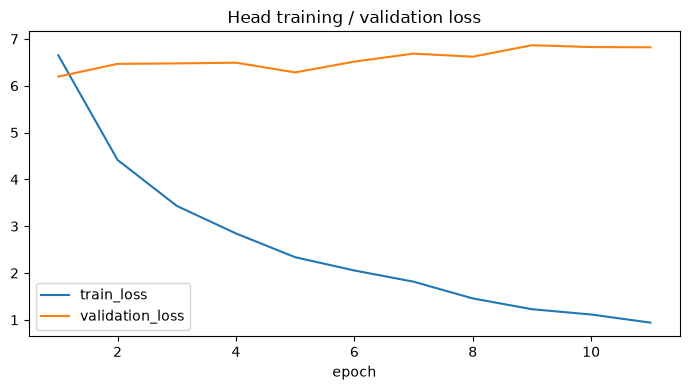

In [9]:
torch.manual_seed(SEED)
head = nn.Sequential(nn.Dropout(0.2), nn.Linear(feature_size, len(class_names))).to(DEVICE)
train_features = features[indices['train']]
train_labels = labels[indices['train']]
loader = DataLoader(TensorDataset(train_features, train_labels), batch_size=BATCH_SIZE, shuffle=True,
                    generator=torch.Generator().manual_seed(SEED), num_workers=0)
training_counts = torch.bincount(train_labels, minlength=len(class_names)).float()
class_weights = (len(train_labels) / (len(class_names) * training_counts)).to(DEVICE) if USE_CLASS_WEIGHTS else None
loss_function = nn.CrossEntropyLoss(weight=class_weights)
optimizer = torch.optim.AdamW(head.parameters(), lr=LEARNING_RATE, weight_decay=0.01)
history = []; best_loss = float('inf'); best_state = None; stale = 0
for epoch in range(1, EPOCHS + 1):
    head.train(); loss_total = 0.0
    for x, y in loader:
        optimizer.zero_grad(set_to_none=True)
        loss = loss_function(head(x.to(DEVICE)), y.to(DEVICE))
        loss.backward(); optimizer.step(); loss_total += loss.item() * len(y)
    head.eval()
    with torch.no_grad():
        val_logits = head(features[indices['validation']].to(DEVICE))
        # Unweighted validation loss is comparable with USE_CLASS_WEIGHTS on/off.
        val_loss = nn.functional.cross_entropy(val_logits, labels[indices['validation']].to(DEVICE)).item()
    val_metrics = score_predictions(labels[indices['validation']], val_logits)[0]
    history.append({'epoch': epoch, 'train_loss': loss_total / len(train_labels), 'validation_loss': val_loss, **val_metrics})
    if val_loss < best_loss - 1e-5:
        best_loss = val_loss; best_state = copy.deepcopy(head.state_dict()); best_epoch = epoch; stale = 0
    else:
        stale += 1
    if epoch == 1 or epoch % 10 == 0:
        print(f'Epoch {epoch}: train loss {history[-1]["train_loss"]:.3f}; val loss {val_loss:.3f}; val macro F1 {val_metrics["macro_f1_evaluated_classes"]:.3f}')
    if stale >= PATIENCE:
        break
head.load_state_dict(best_state); head.eval()
print(f'Restored epoch {best_epoch}; {sum(p.numel() for p in head.parameters()):,} trainable parameters.')
history_df = pd.DataFrame(history).set_index('epoch')
history_df[['train_loss', 'validation_loss']].plot(figsize=(7, 4), title='Head training / validation loss')
plt.tight_layout(); plt.show()

## 10. Final held-out results with class-coverage limits

Evaluate against all 222 possible predictions, but report how many true classes actually have test examples. Unsupported classes remain in the model and are unmeasured. Show only low-recall supported classes and a small confusion submatrix; full per-class metrics stay in memory. Test results must not guide later hyperparameter tuning.

Test represents 82 of 222 classes; 140 are unmeasured.
EXPLORATORY mixed-view results; unreviewed labels/crops and sparse coverage limit interpretation.


,accuracy,macro_f1_evaluated_classes,macro_f1_all_222,top_3_accuracy
training_majority,0.007,0.000,0.000,0.011
centroid,0.039,0.042,0.016,0.086
linear_head,0.014,0.008,0.003,0.032


,precision,recall,f1,support
class,,,,
13-1,0.0,0.0,0.0,1
BENETT ALPHONSO,0.0,0.0,0.0,1
MABRUKA,0.0,0.0,0.0,1
MAMME,0.0,0.0,0.0,1
PO PUY KALAY/ LEMON MERINGUE,0.0,0.0,0.0,1
ROSIGOLD,0.0,0.0,0.0,1
9816,0.0,0.0,0.0,2
ALAMPUR BANESHAN,0.0,0.0,0.0,2
BROOKS,0.0,0.0,0.0,2


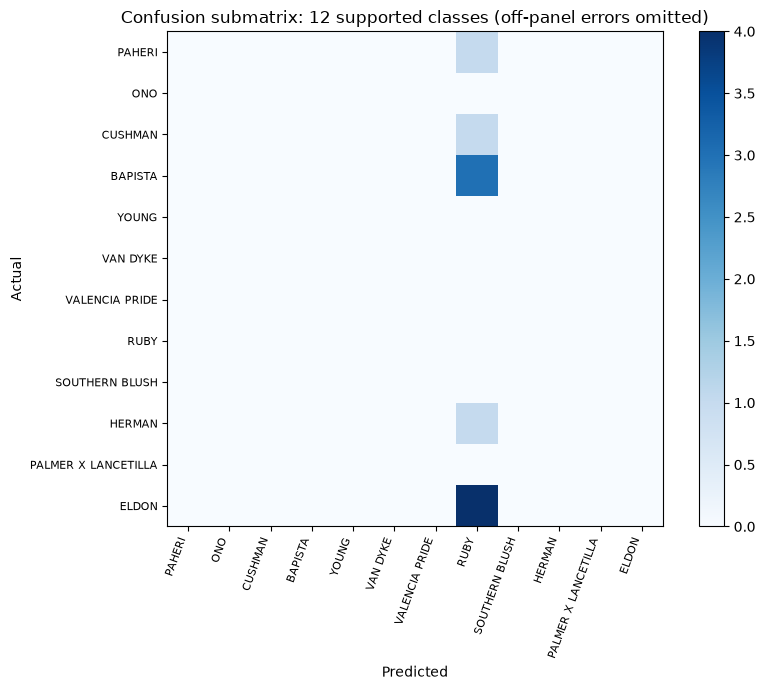

In [10]:
with torch.no_grad():
    head_test_scores = head(features[indices['test']].to(DEVICE)).cpu()
centroid_test_scores = unit_features[indices['test']] @ centroids.T
head_metrics, per_class_metrics, confusion = score_predictions(labels[indices['test']], head_test_scores)
centroid_metrics = score_predictions(labels[indices['test']], centroid_test_scores)[0]
majority_id = int(training_counts.argmax())
majority_scores = torch.zeros((len(indices['test']), len(class_names)))
majority_scores[:, majority_id] = 1
majority_metrics = score_predictions(labels[indices['test']], majority_scores)[0]
display(pd.DataFrame({'training_majority': majority_metrics, 'centroid': centroid_metrics, 'linear_head': head_metrics}).T.round(3))
supported_metrics = per_class_metrics.loc[per_class_metrics.support.gt(0)]
print(f'Test represents {len(supported_metrics)} of {len(class_names)} classes; {len(class_names) - len(supported_metrics)} are unmeasured.')
display(supported_metrics.sort_values(['recall', 'support']).head(12).round(3))
# A submatrix for the 12 most-supported test classes; off-panel predictions are omitted.
plot_classes = supported_metrics.sort_values('support', ascending=False).head(12).index.tolist()
plot_ids = [class_to_id[name] for name in plot_classes]
submatrix = confusion[plot_ids][:, plot_ids]
fig, ax = plt.subplots(figsize=(9, 7))
plot = ax.imshow(submatrix.numpy(), cmap='Blues')
ax.set_xticks(range(len(plot_classes)), plot_classes, rotation=70, ha='right', fontsize=8)
ax.set_yticks(range(len(plot_classes)), plot_classes, fontsize=8)
ax.set_xlabel('Predicted'); ax.set_ylabel('Actual'); ax.set_title('Confusion submatrix: 12 supported classes (off-panel errors omitted)')
fig.colorbar(plot, ax=ax); plt.tight_layout(); plt.show()
print('EXPLORATORY mixed-view results; unreviewed labels/crops and sparse coverage limit interpretation.')

## 11. Save one reproducible experiment artifact

A fresh run directory contains the trained model, class mapping, preprocessing settings, exact split membership, provenance, and metrics as JSON/PyTorch artifacts. No extra CSV reports. The raw annotation mapping CSV remains separate and unchanged.


In [11]:
from datetime import datetime, timezone
run_dir = ML_ROOT / 'runs' / ('full-222-resnet18-' + datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S%fZ'))
run_dir.mkdir(parents=True, exist_ok=False)
checkpoint = {'backbone': {k: v.cpu() for k, v in backbone.state_dict().items()},
              'head': {k: v.cpu() for k, v in head.state_dict().items()}, 'centroids': centroids,
              'class_names': class_names, 'feature_size': feature_size}
torch.save(checkpoint, run_dir / 'model.pt')
experiment = {'seed': SEED, 'backbone': 'resnet18', 'weights': 'IMAGENET1K_V1',
              'torch_version': str(torch.__version__), 'manifest_sha256': hashlib.sha256(manifest_path.read_bytes()).hexdigest(),
              'mode': 'reviewed_crops' if REQUIRE_REVIEWED_CROPS else 'exploratory_mixed_view_full_images',
              'preprocessing': {'image_size': IMAGE_SIZE, 'mean': MEAN, 'std': STD, 'aspect_preserving_padding': True, 'augmentation': False},
              'class_names': class_names, 'normalization': 'case and whitespace only; no spelling merges', 'label_overrides': LABEL_OVERRIDES,
              'reviewed_crops': REVIEWED_CROPS, 'selection': {'expected_classes': EXPECTED_CLASSES, 'views': 'all labeled views', 'training_only_classes': training_only},
              'training': {'epochs_limit': EPOCHS, 'best_epoch': best_epoch, 'patience': PATIENCE,
                           'learning_rate': LEARNING_RATE, 'class_weights': USE_CLASS_WEIGHTS, 'dropout': 0.2, 'weight_decay': 0.01},
              'split_rows': model_df[['raw_path', 'sha256', 'cultivar', 'code', 'group', 'class_id', 'split']].to_dict('records'),
              'test_metrics': {'majority': majority_metrics, 'centroid': centroid_metrics, 'head': head_metrics},
              'history': history_df.reset_index().to_dict('records')}
(run_dir / 'experiment.json').write_text(json.dumps(experiment, indent=2), encoding='utf-8')
print(f'Saved model and experiment record: {run_dir}')

Saved model and experiment record: /Users/danielgeorge/Desktop/coding/cis4914-senior-project-code/ml-models/runs/full-222-resnet18-20261004T190744711354Z


## Interpretation and next steps

This is an all-222-class training experiment, not a complete 222-class benchmark. Preserve training-only class coverage and evaluate supported classes transparently. Review spelling duplicates, fruit-only crops, and specimen identity before claiming real recognition. The exterior-only notebook remains the V1 experiment; compare its results separately because class sets and view scopes differ.

## 12. Continue the baseline with Hugging Face training images

This section can run independently from here using a saved all-222 baseline. It preserves that run's class IDs, crop policy and exact SharePoint splits. Only the HF **train** Parquet files contribute training examples; HF validation/test remain unused. Case/whitespace and explicit retail suffix cleanup are the only label matching rules. Unresolved aliases, abbreviations and labels outside the 222-class catalog are excluded.

Actual fine-tuning unfreezes ResNet **layer4** and the classifier; earlier layers and all BatchNorm statistics/parameters stay frozen. Cached layer3 spatial maps make CPU training practical while gradients still update layer4. This first fine-tuning experiment uses deterministic inputs, no augmentation. All images/labels remain unreviewed whole-image candidates; results are exploratory and reuse a previously inspected SharePoint test set.


In [1]:
from pathlib import Path
import copy, hashlib, io, json, random, re, time
from datetime import datetime, timezone
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from PIL import Image, ImageOps
from pillow_heif import register_heif_opener
import pyarrow.parquet as pq
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
from torchvision.models import resnet18
from torchvision import transforms

register_heif_opener()
ft_here = Path.cwd().resolve()
ft_root = next((p for parent in (ft_here, *ft_here.parents) for p in (parent, parent / 'ml-models')
                if (p / 'data/manifests/sharepoint_gemini/annotations.jsonl').is_file()), None)
if ft_root is None:
    raise FileNotFoundError('Cannot locate ml-models.')
# Explicit baseline: no accidental selection of a later/tuned run.
FT_BASELINE_DIR = ft_root / 'runs/full-222-resnet18-20261004T190744711354Z'
if not (FT_BASELINE_DIR / 'model.pt').is_file():
    raise FileNotFoundError('Run the baseline cells first, then set FT_BASELINE_DIR to the printed run directory.')
FT_SEED = 4914
FT_BATCH_SIZE = 16
FT_EPOCHS = 5
FT_PATIENCE = 2
FT_BLOCK_LR = 1e-5
FT_HEAD_LR = 3e-4
FT_NEAR_DUPLICATE_BITS = 2
random.seed(FT_SEED); np.random.seed(FT_SEED); torch.manual_seed(FT_SEED)
ft_device = torch.device('cuda' if torch.cuda.is_available() else 'mps' if torch.backends.mps.is_available() else 'cpu')
ft_baseline = json.loads((FT_BASELINE_DIR / 'experiment.json').read_text())
ft_checkpoint = torch.load(FT_BASELINE_DIR / 'model.pt', map_location='cpu', weights_only=True)
ft_classes = ft_baseline['class_names']
ft_class_ids = {name: i for i, name in enumerate(ft_classes)}
assert len(ft_classes) == 222 and ft_checkpoint['class_names'] == ft_classes
ft_sp = pd.DataFrame(ft_baseline['split_rows'])
assert ft_sp.loc[ft_sp.split.eq('train'), 'class_id'].nunique() == 222
assert ft_sp.groupby('group').split.nunique().max() == 1
ft_manifest = ft_root / 'data/manifests/sharepoint_gemini/annotations.jsonl'
if hashlib.sha256(ft_manifest.read_bytes()).hexdigest() != ft_baseline['manifest_sha256']:
    raise ValueError('Annotations changed since the baseline; reconcile labels/splits before continuing.')
ft_hf_files = sorted((ft_root / 'data/raw/hugging_face_data/data').glob('train-*.parquet'))
if not ft_hf_files:
    raise FileNotFoundError('Local Hugging Face train Parquet files are missing.')
print(f'Continuing {FT_BASELINE_DIR.name} on {ft_device}; all {len(ft_classes)} outputs retained.')
print(f'Fine-tune up to {FT_EPOCHS} epochs; use SharePoint validation loss for checkpoint selection.')

Continuing full-222-resnet18-20261004T190744711354Z on cpu; all 222 outputs retained.
Fine-tune up to 5 epochs; use SharePoint validation loss for checkpoint selection.


## 13. Match labels and screen additional images

The review below reports accepted/excluded counts, without printing hundreds of labels. Pixel hashes catch identical standardized images; a conservative 64-bit difference-hash check rejects HF images within two bits of any SharePoint image. Suspected matches are excluded from training, regardless of label. This is a screening heuristic and does not establish the absence of all related photos. Conflicting HF pixel-label groups and exact HF duplicates are also excluded. Decode problems are logged in memory and the final experiment record.


In [2]:
def ft_file_hash(path):
    digest = hashlib.sha256()
    with path.open('rb') as handle:
        for chunk in iter(lambda: handle.read(1024 * 1024), b''):
            digest.update(chunk)
    return digest.hexdigest()

def ft_label(text):
    text = re.sub(r'\s+', ' ', str(text)).strip().upper()
    text = re.sub(r'\s*\*PRE-ORDER\*\s*$', '', text).strip()
    return re.sub(r'\s+FRUIT\s*,\s*(GRAFTED|MANGIFERA INDICA)\s*$', '', text).strip()

def ft_prepare(opened, crop=None):
    image = ImageOps.exif_transpose(opened).convert('RGB')
    if crop is not None:
        left, top, right, bottom = crop
        if not (0 <= left < right <= image.width and 0 <= top < bottom <= image.height):
            raise ValueError('Invalid crop after orientation correction.')
        image = image.crop(crop)
    edge = max(image.size)
    square = Image.new('RGB', (edge, edge), (124, 116, 104))
    square.paste(image, ((edge-image.width)//2, (edge-image.height)//2))
    return square.resize((224, 224), Image.Resampling.BILINEAR)

def ft_image_signatures(image):
    pixels = np.asarray(image, dtype=np.uint8).copy()
    small = np.asarray(image.convert('L').resize((9, 8), Image.Resampling.BILINEAR))
    bits = np.packbits((small[:, 1:] > small[:, :-1]).reshape(-1))
    return pixels, hashlib.sha256(pixels.tobytes()).hexdigest(), int.from_bytes(bits.tobytes(), 'big')

ft_rows, ft_images = [], []
ft_sp_dhashes = []
ft_sp_pixel_hashes = set()
for number, row in enumerate(ft_sp.itertuples(), 1):
    path = ft_root / row.raw_path
    if ft_file_hash(path) != row.sha256:
        raise ValueError(f'Source bytes changed since baseline: {row.raw_path}')
    with Image.open(path) as opened:
        crop = ft_baseline.get('reviewed_crops', {}).get(row.raw_path)
        image = ft_prepare(opened, crop)
    pixels, pixel_hash, dhash = ft_image_signatures(image)
    ft_images.append(pixels)
    ft_sp_dhashes.append(dhash); ft_sp_pixel_hashes.add(pixel_hash)
    ft_rows.append({'sample_id': row.raw_path, 'source': 'sharepoint', 'split': row.split,
                    'class_id': int(row.class_id), 'cultivar': row.cultivar, 'group': row.group,
                    'sha256': row.sha256, 'pixel_hash': pixel_hash, 'dhash': str(dhash)})
    if number % 300 == 0:
        print(f'Prepared SharePoint images: {number}/{len(ft_sp)}', flush=True)

ft_exclusions = []
ft_hf_candidates = []
ft_hf_total = 0; ft_hf_matched = 0
ft_hf_provenance = []
for parquet_path in ft_hf_files:
    ft_hf_provenance.append({'file': str(parquet_path.relative_to(ft_root)), 'sha256': ft_file_hash(parquet_path)})
    offset = 0
    for batch in pq.ParquetFile(parquet_path).iter_batches(batch_size=128,
            columns=['variety_name', 'image', 'image_url', 'source_name', 'source_url']):
        for local_index, record in enumerate(batch.to_pylist()):
            row_index = offset + local_index
            ft_hf_total += 1
            label = ft_label(record['variety_name'])
            if label not in ft_class_ids:
                continue
            ft_hf_matched += 1
            sample_id = f'hf:{parquet_path.name}:{row_index}'
            raw_bytes = (record.get('image') or {}).get('bytes')
            try:
                if not raw_bytes:
                    raise ValueError('Missing embedded bytes')
                with Image.open(io.BytesIO(raw_bytes)) as opened:
                    image = ft_prepare(opened)
                pixels, pixel_hash, dhash = ft_image_signatures(image)
            except (OSError, ValueError, Image.DecompressionBombError) as exc:
                ft_exclusions.append({'sample_id': sample_id, 'reason': 'decode_error', 'detail': str(exc)[:160]})
                continue
            if pixel_hash in ft_sp_pixel_hashes:
                ft_exclusions.append({'sample_id': sample_id, 'reason': 'sharepoint_pixel_duplicate'})
                continue
            if any((dhash ^ existing).bit_count() <= FT_NEAR_DUPLICATE_BITS for existing in ft_sp_dhashes):
                ft_exclusions.append({'sample_id': sample_id, 'reason': 'suspected_sharepoint_near_duplicate'})
                continue
            ft_hf_candidates.append(({'sample_id': sample_id, 'source': 'huggingface', 'split': 'train',
                'class_id': ft_class_ids[label], 'cultivar': label, 'group': record.get('source_url') or sample_id,
                'sha256': hashlib.sha256(raw_bytes).hexdigest(), 'pixel_hash': pixel_hash, 'dhash': str(dhash),
                'hf_parquet': str(parquet_path.relative_to(ft_root)), 'hf_row_index': row_index,
                'hf_original_split': 'train', 'raw_label': record['variety_name'],
                'source_name': record.get('source_name'), 'source_url': record.get('source_url'),
                'image_url': record.get('image_url')}, pixels))
        offset += batch.num_rows
        if offset % 512 == 0:
            print(f'Scanned HF training records: {offset}', flush=True)

ft_hash_classes = {}
for record, _ in ft_hf_candidates:
    ft_hash_classes.setdefault(record['pixel_hash'], set()).add(record['class_id'])
ft_seen = set()
for record, pixels in ft_hf_candidates:
    key = record['pixel_hash']
    if len(ft_hash_classes[key]) > 1:
        ft_exclusions.append({'sample_id': record['sample_id'], 'reason': 'conflicting_hf_pixel_labels'})
    elif key in ft_seen:
        ft_exclusions.append({'sample_id': record['sample_id'], 'reason': 'hf_pixel_duplicate'})
    else:
        ft_seen.add(key); ft_rows.append(record); ft_images.append(pixels)
del ft_hf_candidates
ft_data = pd.DataFrame(ft_rows)
ft_hf_accepted = ft_data.loc[ft_data.source.eq('huggingface')]
if ft_hf_accepted.empty:
    raise ValueError('No matching HF images survived screening.')
assert ft_hf_accepted.split.eq('train').all()
assert ft_hf_accepted.hf_original_split.eq('train').all()
assert not set(ft_hf_accepted.pixel_hash) & ft_sp_pixel_hashes
assert ft_data.loc[ft_data.split.eq('train'), 'class_id'].nunique() == 222
# Exact SharePoint sample/split identity is preserved, including row order.
assert ft_data.iloc[:len(ft_sp)].sample_id.tolist() == ft_sp.raw_path.tolist()
assert ft_data.iloc[:len(ft_sp)].split.tolist() == ft_sp.split.tolist()
ft_summary = pd.DataFrame({'measure': ['HF train rows scanned', 'Label-matched candidates', 'Accepted additional images',
                                      'Classes receiving HF images', 'Combined training images', 'Fixed validation / test images'],
    'value': [ft_hf_total, ft_hf_matched, len(ft_hf_accepted), ft_hf_accepted.cultivar.nunique(),
              int(ft_data.split.eq('train').sum()), f"{ft_data.split.eq('validation').sum()} / {ft_data.split.eq('test').sum()}"]})
display(ft_summary.set_index('measure'))
if ft_exclusions:
    display(pd.Series([r['reason'] for r in ft_exclusions]).value_counts().rename('excluded').to_frame())
print('HF view type and label correctness are unverified; label matching is not image approval.')

Prepared SharePoint images: 300/1386
Prepared SharePoint images: 600/1386
Prepared SharePoint images: 900/1386
Prepared SharePoint images: 1200/1386
Scanned HF training records: 512
Scanned HF training records: 1024
Scanned HF training records: 1536
Scanned HF training records: 2048
Scanned HF training records: 2560
Scanned HF training records: 3072
HF view type and label correctness are unverified; label matching is not image approval.


,value
measure,
HF train rows scanned,3093
Label-matched candidates,1586
Accepted additional images,1586
Classes receiving HF images,56
Combined training images,2579
Fixed validation / test images,113 / 280


## 14. Preview the additional training inputs

Show six accepted HF candidates with their mapped cultivar names. These are examples, not a completed visual review. The data loader uses the same RGB padding and normalization as the baseline.

The saved preview includes saplings/foliage and food preparation alongside fruit. The additional records pass label/decode/duplicate checks, but they are **not a fruit-only reviewed dataset**. Interpret this run as an experiment with unreviewed external data; a later curated experiment should exclude unsuitable views.


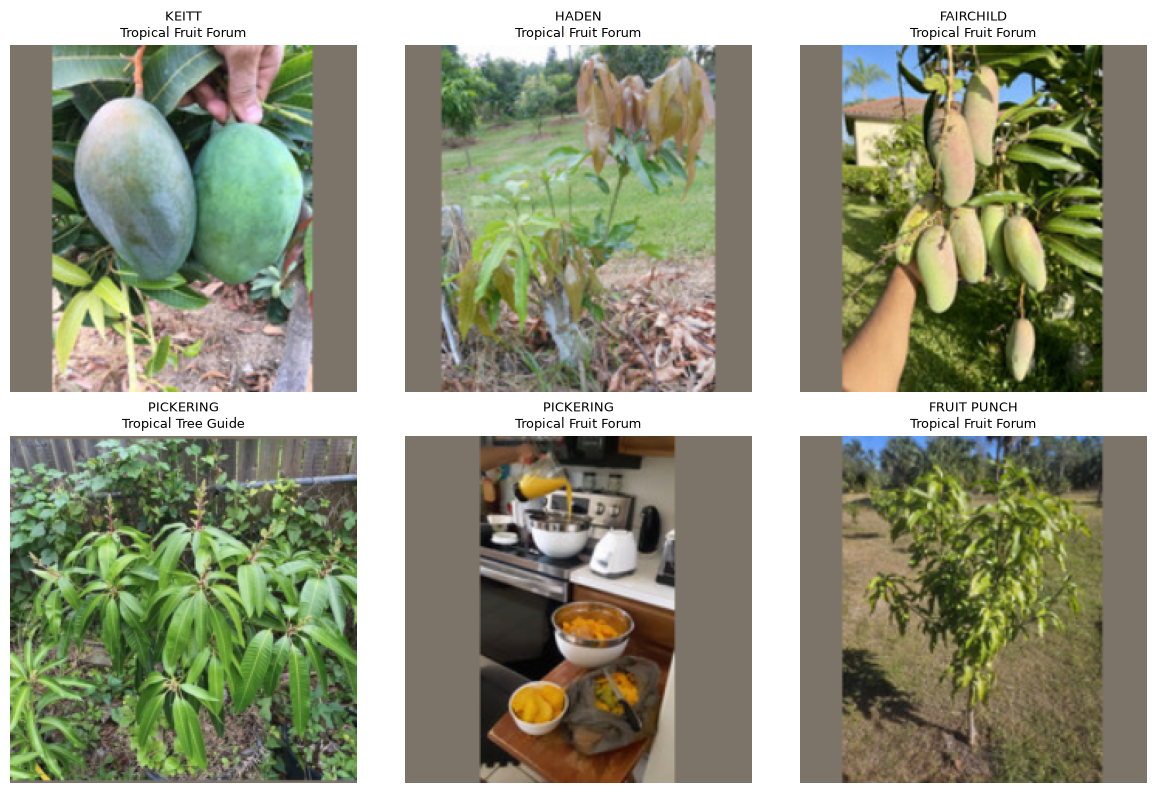

In [3]:
ft_preview = ft_hf_accepted.sample(min(6, len(ft_hf_accepted)), random_state=FT_SEED)
fig, axes = plt.subplots(2, 3, figsize=(12, 8))
for ax, (index, row) in zip(axes.flat, ft_preview.iterrows()):
    ax.imshow(ft_images[index]); ax.set_title(f'{row.cultivar}\n{row.source_name}', fontsize=9)
for ax in axes.flat:
    ax.axis('off')
plt.tight_layout(); plt.show()

## 15. Cache the frozen early layers

The cache contains layer3 spatial maps, **before** the trainable layer4. It is keyed by source/split/preprocessing metadata, standardized image hashes and the baseline checkpoint. Float32 maps preserve the baseline computation. All later optimization uses training indices only.


In [4]:
ft_network = resnet18(weights=None)
ft_network.fc = nn.Identity()
ft_network.load_state_dict(ft_checkpoint['backbone'], strict=True)
ft_network.requires_grad_(False)
ft_trunk = nn.Sequential(*list(ft_network.children())[:-3]).to(ft_device).eval()
ft_head = nn.Sequential(nn.Dropout(0.2), nn.Linear(512, 222))
ft_head.load_state_dict(ft_checkpoint['head'])
ft_block = ft_network.layer4.to(ft_device)
ft_model = nn.Sequential(ft_block, nn.AdaptiveAvgPool2d(1), nn.Flatten(), ft_head).to(ft_device).eval()
ft_normalize = transforms.Normalize(ft_baseline['preprocessing']['mean'], ft_baseline['preprocessing']['std'])
ft_cache_spec = {'version': 1, 'baseline_model': ft_file_hash(FT_BASELINE_DIR / 'model.pt'),
    'preprocessing': ft_baseline['preprocessing'], 'layer': 'layer3', 'dtype': 'float32',
    'rows': ft_data[['sample_id', 'pixel_hash', 'class_id', 'split']].to_dict('records')}
ft_cache_key = hashlib.sha256(json.dumps(ft_cache_spec, sort_keys=True).encode()).hexdigest()
ft_cache_dir = ft_root / 'runs/.hf-finetune-cache'
ft_cache_dir.mkdir(parents=True, exist_ok=True)
ft_cache_file = ft_cache_dir / f'{ft_cache_key}.pt'
if ft_cache_file.is_file():
    ft_maps = torch.load(ft_cache_file, map_location='cpu', weights_only=True)
    print('Loaded matching frozen-layer feature cache.')
else:
    ft_chunks = []; ft_start = time.time()
    with torch.inference_mode():
        for start in range(0, len(ft_images), FT_BATCH_SIZE):
            arrays = np.stack(ft_images[start:start + FT_BATCH_SIZE])
            inputs = torch.from_numpy(arrays).permute(0, 3, 1, 2).float().div_(255.0)
            inputs = ft_normalize(inputs).to(ft_device)
            ft_chunks.append(ft_trunk(inputs).cpu())
            if (start // FT_BATCH_SIZE) % 20 == 0:
                print(f'Frozen layers: {min(start + FT_BATCH_SIZE, len(ft_images))}/{len(ft_images)} images; {time.time()-ft_start:.0f}s', flush=True)
    ft_maps = torch.cat(ft_chunks).clone()
    del ft_chunks
    torch.save(ft_maps, ft_cache_file)
assert ft_maps.shape == (len(ft_data), 256, 14, 14)
assert torch.isfinite(ft_maps).all()
del ft_images
ft_labels = torch.tensor(ft_data.class_id.to_numpy(), dtype=torch.long)
ft_indices = {name: torch.tensor(np.flatnonzero(ft_data.split.eq(name).to_numpy()), dtype=torch.long)
              for name in ['train', 'validation', 'test']}
print(f'Cached {tuple(ft_maps.shape)} spatial maps; {len(ft_indices["train"])} training images.')

Frozen layers: 16/2972 images; 0s
Frozen layers: 336/2972 images; 4s
Frozen layers: 656/2972 images; 8s
Frozen layers: 976/2972 images; 12s
Frozen layers: 1296/2972 images; 17s
Frozen layers: 1616/2972 images; 22s
Frozen layers: 1936/2972 images; 26s
Frozen layers: 2256/2972 images; 31s
Frozen layers: 2576/2972 images; 35s
Frozen layers: 2896/2972 images; 40s
Cached (2972, 256, 14, 14) spatial maps; 2579 training images.


## 16. Fine-tune layer4 and the classifier

Train at small learning rates for at most five epochs, selecting the best checkpoint by the original SharePoint validation loss. Each source contributes half of the total training loss across an epoch, so the larger source cannot dominate simply through its row count. BatchNorm remains frozen. Every training row is visited each epoch. No test data is used for selection.


Epoch 1: 640/2579 training images
Epoch 1: 1280/2579 training images
Epoch 1: 1920/2579 training images
Epoch 1: 2560/2579 training images
Epoch 1: train 4.374, validation 5.150, val accuracy 8.8%, 25s
Epoch 2: 640/2579 training images
Epoch 2: 1280/2579 training images
Epoch 2: 1920/2579 training images
Epoch 2: 2560/2579 training images
Epoch 2: train 3.598, validation 5.274, val accuracy 5.3%, 28s
Epoch 3: 640/2579 training images
Epoch 3: 1280/2579 training images
Epoch 3: 1920/2579 training images
Epoch 3: 2560/2579 training images
Epoch 3: train 3.079, validation 5.561, val accuracy 8.0%, 30s
Restored fine-tuned epoch 1; validation loss 6.195 -> 5.150.
Updated layer4/head; frozen early layers verified unchanged. Trainable parameters: 8,502,494.


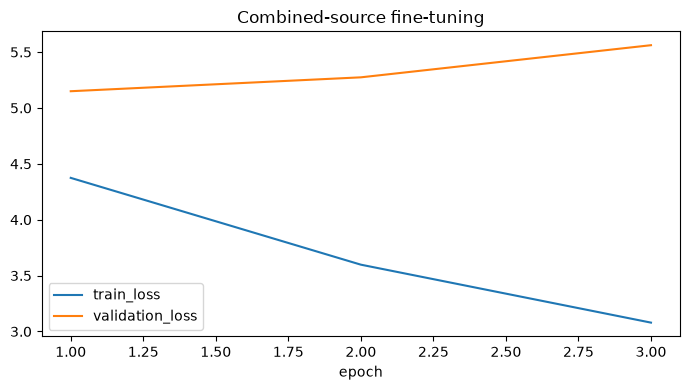

In [5]:
def ft_scores(index, model=ft_model):
    model.eval(); chunks = []
    with torch.no_grad():
        for start in range(0, len(index), FT_BATCH_SIZE):
            chunks.append(model(ft_maps[index[start:start + FT_BATCH_SIZE]].to(ft_device)).cpu())
    return torch.cat(chunks)

def ft_metrics(y, logits):
    pred = logits.argmax(1)
    cm = torch.bincount(y * 222 + pred, minlength=222 * 222).reshape(222, 222).float()
    tp = cm.diag(); support = cm.sum(1)
    precision = tp / cm.sum(0).clamp_min(1); recall = tp / support.clamp_min(1)
    f1 = 2 * precision * recall / (precision + recall).clamp_min(1e-12)
    return {'accuracy': float(pred.eq(y).float().mean()),
            'macro_f1_evaluated_classes': float(f1[support.gt(0)].mean()),
            'macro_f1_all_222': float(f1.mean()),
            'top_3_accuracy': float(logits.topk(3, dim=1).indices.eq(y[:, None]).any(1).float().mean()),
            'evaluated_classes': int(support.gt(0).sum()), 'images': len(y)}

ft_initial_validation = ft_scores(ft_indices['validation'])
ft_initial_validation_loss = nn.functional.cross_entropy(ft_initial_validation, ft_labels[ft_indices['validation']]).item()
# Save the unchanged baseline test logits before layer4 is updated; inspect only after training.
ft_baseline_test_logits = ft_scores(ft_indices['test'])
ft_frozen_snapshot = {key: value.detach().cpu().clone() for key, value in ft_trunk.state_dict().items()}
ft_block.requires_grad_(True); ft_head.requires_grad_(True)
for module in ft_model.modules():
    if isinstance(module, nn.BatchNorm2d):
        module.requires_grad_(False)
ft_trainable_before = {key: value.detach().cpu().clone() for key, value in ft_model.named_parameters() if value.requires_grad}
ft_optimizer = torch.optim.AdamW([
    {'params': [p for p in ft_block.parameters() if p.requires_grad], 'lr': FT_BLOCK_LR},
    {'params': ft_head.parameters(), 'lr': FT_HEAD_LR}], weight_decay=0.01)
ft_source_counts = ft_data.loc[ft_data.split.eq('train'), 'source'].value_counts()
ft_row_weights = torch.tensor([len(ft_indices['train']) / (len(ft_source_counts) * ft_source_counts[source])
    if split == 'train' else 1.0 for source, split in zip(ft_data.source, ft_data.split)], dtype=torch.float32)
ft_loader = DataLoader(TensorDataset(ft_indices['train']), batch_size=FT_BATCH_SIZE, shuffle=True,
                       generator=torch.Generator().manual_seed(FT_SEED), num_workers=0)
ft_history = []; ft_best_loss = float('inf'); ft_best_state = None; ft_stale = 0
torch.manual_seed(FT_SEED)
for epoch in range(1, FT_EPOCHS + 1):
    ft_model.train()
    for module in ft_model.modules():
        if isinstance(module, nn.BatchNorm2d):
            module.eval()
    weighted_loss_sum = 0.0; seen = 0; epoch_start = time.time()
    for (batch_index,) in ft_loader:
        ft_optimizer.zero_grad(set_to_none=True)
        logits = ft_model(ft_maps[batch_index].to(ft_device))
        losses = nn.functional.cross_entropy(logits, ft_labels[batch_index].to(ft_device), reduction='none')
        loss = (losses * ft_row_weights[batch_index].to(ft_device)).mean()
        if not torch.isfinite(loss):
            raise ValueError('Nonfinite fine-tuning loss; stop and inspect the inputs/configuration.')
        loss.backward(); torch.nn.utils.clip_grad_norm_(ft_model.parameters(), 1.0); ft_optimizer.step()
        weighted_loss_sum += loss.item() * len(batch_index); seen += len(batch_index)
        if seen % (FT_BATCH_SIZE * 40) == 0:
            print(f'Epoch {epoch}: {seen}/{len(ft_indices["train"])} training images', flush=True)
    validation_logits = ft_scores(ft_indices['validation'])
    val_loss = nn.functional.cross_entropy(validation_logits, ft_labels[ft_indices['validation']]).item()
    metrics = ft_metrics(ft_labels[ft_indices['validation']], validation_logits)
    ft_history.append({'epoch': epoch, 'train_loss': weighted_loss_sum / seen, 'validation_loss': val_loss, **metrics})
    if val_loss < ft_best_loss - 1e-5:
        ft_best_loss = val_loss; ft_best_epoch = epoch; ft_stale = 0
        ft_best_state = {key: value.detach().cpu().clone() for key, value in ft_model.state_dict().items()}
    else:
        ft_stale += 1
    print(f'Epoch {epoch}: train {weighted_loss_sum/seen:.3f}, validation {val_loss:.3f}, val accuracy {metrics["accuracy"]:.1%}, {time.time()-epoch_start:.0f}s', flush=True)
    if ft_stale >= FT_PATIENCE:
        break
assert ft_best_state is not None
ft_model.load_state_dict(ft_best_state); ft_model.eval()
assert all(torch.equal(value.detach().cpu(), ft_frozen_snapshot[key]) for key, value in ft_trunk.state_dict().items())
assert any(not torch.equal(value.detach().cpu(), ft_trainable_before[key]) for key, value in ft_model.named_parameters()
           if value.requires_grad and key.startswith('0.'))
print(f'Restored fine-tuned epoch {ft_best_epoch}; validation loss {ft_initial_validation_loss:.3f} -> {ft_best_loss:.3f}.')
print(f'Updated layer4/head; frozen early layers verified unchanged. Trainable parameters: {sum(p.numel() for p in ft_model.parameters() if p.requires_grad):,}.')
pd.DataFrame(ft_history).set_index('epoch')[['train_loss', 'validation_loss']].plot(figsize=(7, 4), title='Combined-source fine-tuning')
plt.tight_layout(); plt.show()

## 17. Compare on the identical SharePoint test set

This is a continued exploratory benchmark on the same previously inspected test set. It evaluates only its 82 supported classes while predictions still compete across all 222 outputs. It does not establish HF performance or results for training-only classes. Changes reflect both additional data and upper-layer fine-tuning; they cannot be attributed solely to HF.


In [6]:
ft_test_logits = ft_scores(ft_indices['test'])
ft_before_metrics = ft_metrics(ft_labels[ft_indices['test']], ft_baseline_test_logits)
ft_after_metrics = ft_metrics(ft_labels[ft_indices['test']], ft_test_logits)
assert abs(ft_before_metrics['accuracy'] - ft_baseline['test_metrics']['head']['accuracy']) < 1e-7
ft_comparison = pd.DataFrame({'SharePoint frozen baseline': ft_before_metrics,
                              'SP + HF layer4 fine-tuned': ft_after_metrics}).T
ft_display = ft_comparison[['accuracy', 'top_3_accuracy', 'macro_f1_evaluated_classes', 'evaluated_classes', 'images']].copy()
for key in ['accuracy', 'top_3_accuracy']:
    ft_display[key] = ft_display[key].map(lambda value: f'{value:.1%}')
display(ft_display)
# Compact subgroup view: performance on classes that did/did not receive HF images.
ft_hf_class_ids = set(ft_hf_accepted.class_id)
ft_test_targets = ft_labels[ft_indices['test']]
ft_test_mask = torch.tensor([int(label) in ft_hf_class_ids for label in ft_test_targets])
ft_subgroups = []
for name, mask in [('HF-supported classes', ft_test_mask), ('No matching HF additions', ~ft_test_mask)]:
    if mask.any():
        ft_subgroups.append({'group': name, 'images': int(mask.sum()), 'classes': int(ft_test_targets[mask].unique().numel()),
            'baseline_accuracy': float(ft_baseline_test_logits[mask].argmax(1).eq(ft_test_targets[mask]).float().mean()),
            'fine_tuned_accuracy': float(ft_test_logits[mask].argmax(1).eq(ft_test_targets[mask]).float().mean())})
display(pd.DataFrame(ft_subgroups).set_index('group').round(3))
print(f'{len(ft_hf_accepted)} HF training images added across {len(ft_hf_class_ids)} classes; all 222 outputs retained.')
print('Whole-image shortcuts, unverified labels, source differences and missing test classes remain limitations.')

1586 HF training images added across 56 classes; all 222 outputs retained.
Whole-image shortcuts, unverified labels, source differences and missing test classes remain limitations.


,accuracy,top_3_accuracy,macro_f1_evaluated_classes,evaluated_classes,images
SharePoint frozen baseline,1.4%,3.2%,0.008287,82.0,280.0
SP + HF layer4 fine-tuned,2.1%,4.6%,0.016901,82.0,280.0


,images,classes,baseline_accuracy,fine_tuned_accuracy
group,,,,
HF-supported classes,89,29,0.000,0.045
No matching HF additions,191,53,0.021,0.010


## 18. Save the fine-tuned model and provenance

Create one new run with model weights and a JSON experiment record. It includes original SharePoint splits, exact accepted HF Parquet row IDs/labels/sources, exclusions, cache identity, learning rates and validation history. No CSV reports are generated.


In [7]:
ft_run_dir = ft_root / 'runs' / ('full-222-hf-finetune-' + datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S%fZ'))
ft_run_dir.mkdir(parents=True, exist_ok=False)
# ft_network shares the frozen trunk and updated layer4 modules with the trained model.
ft_saved = {'backbone': {key: value.detach().cpu() for key, value in ft_network.state_dict().items()},
            'head': {key: value.detach().cpu() for key, value in ft_head.state_dict().items()},
            'class_names': ft_classes, 'feature_size': 512}
torch.save(ft_saved, ft_run_dir / 'model.pt')
ft_config = {'seed': FT_SEED, 'epochs_limit': FT_EPOCHS, 'patience': FT_PATIENCE, 'batch_size': FT_BATCH_SIZE,
             'layer4_lr': FT_BLOCK_LR, 'head_lr': FT_HEAD_LR, 'weight_decay': 0.01, 'gradient_clip': 1.0,
             'source_loss_weighting': 'equal total weight per source each epoch', 'trainable': 'layer4 convolutions and classifier',
             'batchnorm': 'all affine parameters and statistics frozen', 'augmentation': False,
             'near_duplicate_threshold_bits': FT_NEAR_DUPLICATE_BITS, 'best_epoch': ft_best_epoch}
ft_record = {'baseline_run': str(FT_BASELINE_DIR.relative_to(ft_root)), 'baseline_model_sha256': ft_cache_spec['baseline_model'],
    'torch_version': str(torch.__version__), 'class_names': ft_classes, 'preprocessing': ft_baseline['preprocessing'],
    'reviewed_crops': ft_baseline.get('reviewed_crops', {}), 'mode': ft_baseline['mode'], 'configuration': ft_config,
    'hf_label_policy': 'case/whitespace plus explicit retail suffix removal; exact match to existing 222 labels; no fuzzy merges',
    'hf_dataset': 'earl562/mango-varieties', 'hf_pinned_download_revision': 'f482454c26bcab8137b0eed3e45317e8bf6ff260',
    'hf_parquet_files': ft_hf_provenance, 'accepted_hf_count': len(ft_hf_accepted), 'hf_supported_classes': sorted(ft_hf_accepted.cultivar.unique()),
    'rows': json.loads(ft_data.to_json(orient='records')), 'exclusions': ft_exclusions, 'feature_cache_key': ft_cache_key,
    'validation_before_loss': ft_initial_validation_loss, 'validation_best_loss': ft_best_loss, 'history': ft_history,
    'test_metrics_before': ft_before_metrics, 'test_metrics_after': ft_after_metrics, 'test_subgroups': ft_subgroups,
    'evaluation_note': 'same previously inspected SharePoint test; exploratory continued benchmark, not a new untouched test'}
(ft_run_dir / 'experiment.json').write_text(json.dumps(ft_record, indent=2), encoding='utf-8')
ft_reloaded = torch.load(ft_run_dir / 'model.pt', map_location='cpu', weights_only=True)
assert ft_reloaded['head']['1.weight'].shape == (222, 512)
assert ft_reloaded['class_names'] == ft_classes
print(f'Saved and checked fine-tuned checkpoint: {ft_run_dir}')

Saved and checked fine-tuned checkpoint: /Users/danielgeorge/Desktop/coding/cis4914-senior-project-code/ml-models/runs/full-222-hf-finetune-20261004T192139020172Z
